Total observations: 300


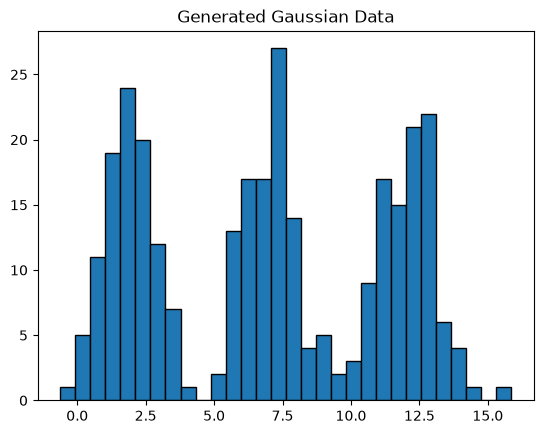

C:\Users\NGOSA\.conda\envs\ICD341\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


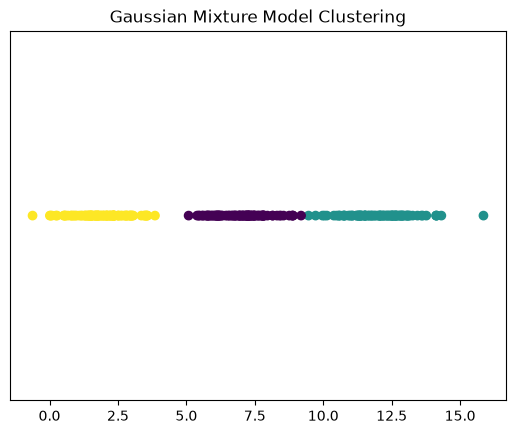

C:\Users\NGOSA\.conda\envs\ICD341\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\NGOSA\.conda\envs\ICD341\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\NGOSA\.conda\envs\ICD341\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\NGOSA\.conda\envs\ICD341\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is k

Estimated Means: [ 6.98734645 12.04041718  1.89614955]
Estimated Variances: [0.8221013  1.19793122 0.81819915]
Mixing Proportions: [0.32957963 0.33717043 0.33324994]
Components: 1, BIC: 1733.11
Components: 2, BIC: 1655.28
Components: 3, BIC: 1526.83
Components: 4, BIC: 1545.74


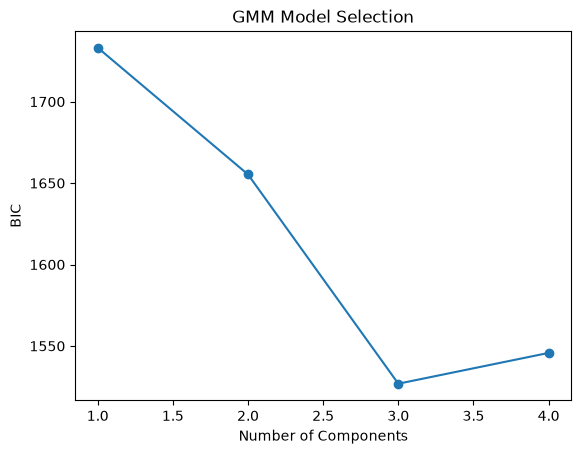

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

# 1. Generate the dataset
np.random.seed(42)
group1 = np.random.normal(2, 1, 100)
group2 = np.random.normal(7, 1, 100)
group3 = np.random.normal(12, 1, 100)
data = np.concatenate([group1, group2, group3])
X = data.reshape(-1, 1)
print("Total observations:", len(X))

# Visualize
plt.hist(X, bins=30, edgecolor="black")
plt.title("Generated Gaussian Data")
plt.show()

# 2. Apply the EM Algorithm
gmm = GaussianMixture(n_components=3, random_state=42)
gmm.fit(X)
labels = gmm.predict(X)

# Plot Clustering
plt.scatter(X[:, 0], np.zeros(len(X)), c=labels, cmap="viridis")
plt.title("Gaussian Mixture Model Clustering")
plt.yticks([])
plt.show()

# 3. Estimate Model Parameters
print("Estimated Means:", gmm.means_.flatten())
print("Estimated Variances:", gmm.covariances_.flatten())
print("Mixing Proportions:", gmm.weights_)

# 4. Evaluate GMM Model (BIC)
components = [1, 2, 3, 4]
bic_values = []
for k in components:
    model = GaussianMixture(n_components=k, random_state=42)
    model.fit(X)
    bic = model.bic(X)
    bic_values.append(bic)
    print(f"Components: {k}, BIC: {bic:.2f}")

plt.plot(components, bic_values, marker="o")
plt.xlabel("Number of Components")
plt.ylabel("BIC")
plt.title("GMM Model Selection")
plt.show()

1. Define the EM algorithm.

- The Expectation-Maximization (EM) algorithm is an iterative method used to find maximum likelihood estimates of parameters in statistical models that depend on unobserved latent variables. It alternates between estimating the hidden variables (E-step) and updating the parameters (M-step).
 
2. What is a Gaussian Mixture Model?

- A Gaussian Mixture Model (GMM) is a probabilistic model that assumes all the data points are generated from a mixture of a finite number of Gaussian distributions with unknown parameters. It is used for clustering and density estimation.
 
3. Explain the difference between the E-step and M-step.

- E-step (Expectation): Calculates the probability that each data point belongs to each of the clusters (the "responsibilities") based on the current parameters.
- M-step (Maximization): Updates the model parameters (means, variances, and mixing weights) to maximize the likelihood of the data given the responsibilities calculated in the E-step.

5. Why is clustering important in statistical computing?

- Clustering is a form of unsupervised learning that helps discover natural groupings, hidden patterns, and structures in unlabeled data. It is widely used for market segmentation, image analysis, and anomaly detection.
 
6. What is the purpose of n_components?

- In scikit-learn's GaussianMixture, n_components specifies the number of mixture components (i.e., the number of clusters or Gaussian distributions) the model should try to fit to the data.
 
7. Explain the importance of BIC.

- The Bayesian Information Criterion (BIC) is a metric used for model selection. It evaluates the goodness of fit while penalizing models that have too many parameters. A lower BIC value indicates a better model because it balances accuracy with simplicity (avoiding overfitting).
 
8. What does the fit() function do?
- The fit() function trains the GMM model on the provided dataset. It runs the iterative EM algorithm to learn the optimal means, covariances, and weights for the Gaussian distributions.
 
9. Mention two practical applications of GMM.
   - Image Segmentation: Grouping pixels with similar colors or textures to identify objects in an image.
   - Speaker Recognition: Modeling the voice characteristics of different speakers to identify who is talking.